# 71 ? Embeddings MPNet + K-Means e categoriza??o revisada

Este notebook investiga embeddings densos de descri??es de itens fiscais como representa??o alternativa ao TF-IDF do notebook 70. O fluxo segue a mesma l?gica: separar valida??o, comparar configura??es de clustering, inspecionar grupos, definir r?tulos humanos e avaliar a reserva.

Usa `sentence-transformers/paraphrase-multilingual-mpnet-base-v2`, variante multil?ngue baseada em MPNet, adequada para incluir portugu?s. O modelo gera um vetor por descri??o; K-Means agrupa esses vetores. MPNet ? um m?todo de pr?-treinamento de linguagem, n?o um autoencoder cl?ssico que reconstr?i a entrada.

**Como usar:** ajuste os par?metros e execute as c?lulas at? a revis?o. Depois edite `cluster_review.csv`, escolha um experimento e preencha `validation_labels.csv` antes de executar a avalia??o. A taxonomia depende de revis?o humana; o notebook n?o atribui categorias automaticamente.

A primeira execu??o baixa o modelo pr?-treinado do Hugging Face e requer `sentence-transformers`, que n?o faz parte das depend?ncias atuais do projeto. Instale essa depend?ncia no ambiente antes de executar, conforme autoriza??o do projeto. Os dados e artefatos existentes s?o preservados; cada execu??o usa uma pasta pr?pria.


In [7]:
import json
import logging
from datetime import datetime, timezone
from hashlib import sha256
from pathlib import Path
from uuid import uuid4

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.metrics import (accuracy_score, calinski_harabasz_score,
                             classification_report, confusion_matrix,
                             davies_bouldin_score, silhouette_score)
from sklearn.model_selection import train_test_split

try:
    from sentence_transformers import SentenceTransformer
except ImportError as exc:
    raise ImportError(
        "Este notebook requer sentence-transformers. A depend?ncia ainda n?o est? "
        "declarada no projeto; instale-a no ambiente ap?s aprova??o."
    ) from exc

from nofis_classifier.schema import DESCRIPTION_NORMALIZED, FREQUENCY

logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
logger = logging.getLogger("notebook71")
pd.set_option("display.max_colwidth", 160)


## 1. Par?metros do experimento

A divis?o ? feita por descri??o ?nica. Descri??es repetidas s?o consolidadas somando `frequencia`; esse valor pondera o ajuste do K-Means. Os embeddings e as m?tricas de valida??o continuam no n?vel de descri??o ?nica.

A grade pequena de `k` ? intencional: K-Means com vetores densos tem custo diferente da matriz esparsa TF-IDF do notebook 70. Aumente a grade ap?s conferir o tempo e a mem?ria dispon?veis.


In [8]:
RUN_ID = None  # Deixe None para criar uma execu??o nova; cada RUN_ID ? de uso ?nico.
DATASET_NAME = "items-notas-fiscais-filtros-combinados-experimentos-texto"
PERIOD_LABEL = "202501-202504"
DATASET_PATH = Path(r"C:\Users\samue\Scripts\Nofis-Classifier\data\processed\items-notas-fiscais-filtros-combinados-experimentos-texto\items-notas-fiscais-filtros-combinados-experimentos-texto-202501-202504.parquet")
MODEL_NAME = "sentence-transformers/paraphrase-multilingual-mpnet-base-v2"
MAX_DESCRIPTIONS = None  # None usa a base toda; use limite pequeno para ensaio r?pido.
VALIDATION_COUNT = 300
SPLIT_SEED = 42
K_VALUES = [10, 20, 30, 40, 2000, 3000]
SEEDS = [42, 123, 2026]
N_INIT = 10
MAX_ITER = 300
METRIC_SAMPLE_SIZE = 1_000
TOP_COMBINATIONS = 3
ENCODE_BATCH_SIZE = 64


## 2. Carregar, dividir e gerar embeddings

A reserva n?o participa do ajuste do K-Means nem da sele??o de candidatos. O modelo pr?-treinado est? fixo; calculamos embeddings do treino e da reserva separadamente para manter expl?cita a fronteira de avalia??o. O CSV de descri??es reservadas ? criado sem r?tulos e n?o deve ser preenchido consultando previs?es.


In [ ]:
items = pd.read_parquet(DATASET_PATH)
required = [DESCRIPTION_NORMALIZED, FREQUENCY]
missing = set(required) - set(items.columns)
if missing:
    raise ValueError(f"Colunas ausentes: {sorted(missing)}")
frequency_before = items[FREQUENCY].sum()
items[DESCRIPTION_NORMALIZED] = items[DESCRIPTION_NORMALIZED].astype("string").str.strip()
items = items[items[DESCRIPTION_NORMALIZED].notna() & items[DESCRIPTION_NORMALIZED].ne("")]
items = items[items[FREQUENCY] >= 1].copy()
items = (
    items.groupby(DESCRIPTION_NORMALIZED, as_index=False, sort=False)[FREQUENCY]
    .sum()
)
if items[FREQUENCY].sum() != frequency_before:
    raise ValueError("A soma de frequ?ncia mudou durante a prepara??o.")
items = items.sort_values(DESCRIPTION_NORMALIZED).reset_index(drop=True)
items.insert(0, "descricao_id", np.arange(len(items), dtype=np.int64))
if MAX_DESCRIPTIONS is not None:
    items = items.sample(n=min(MAX_DESCRIPTIONS, len(items)), random_state=SPLIT_SEED)
    items = items.sort_values(DESCRIPTION_NORMALIZED).reset_index(drop=True)
    items["descricao_id"] = np.arange(len(items), dtype=np.int64)
if not 0 < VALIDATION_COUNT < len(items) - 1:
    raise ValueError("VALIDATION_COUNT deve deixar pelo menos duas descri??es no treino.")
train, validation = train_test_split(items, test_size=VALIDATION_COUNT, random_state=SPLIT_SEED)
train = train.sort_values("descricao_id").reset_index(drop=True)
validation = validation.sort_values("descricao_id").reset_index(drop=True)
assert set(train.descricao_id).isdisjoint(validation.descricao_id)
assert all(2 <= k < len(train) for k in K_VALUES)

RUN_ID = RUN_ID or datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "_" + uuid4().hex[:8]
if not all(c.isalnum() or c in "_-" for c in RUN_ID):
    raise ValueError("RUN_ID inv?lido.")
REPORT_DIR = Path("reports/mpnet_kmeans") / f"{PERIOD_LABEL}_{RUN_ID}"
MODEL_DIR = Path("models/mpnet_kmeans") / f"{PERIOD_LABEL}_{RUN_ID}"
REPORT_DIR.mkdir(parents=True, exist_ok=False)
MODEL_DIR.mkdir(parents=True, exist_ok=False)

metadata = {
    "run_id": RUN_ID, "dataset": DATASET_NAME, "period": PERIOD_LABEL,
    "frequency_weighted": True,
    "dataset_sha256": sha256(pd.util.hash_pandas_object(items, index=True).values.tobytes()).hexdigest(),
    "model_name": MODEL_NAME, "validation_count": VALIDATION_COUNT,
    "split_seed": SPLIT_SEED, "k_values": K_VALUES, "seeds": SEEDS,
}
(REPORT_DIR / "run.json").write_text(json.dumps(metadata, indent=2, ensure_ascii=False), encoding="utf-8")
train.to_csv(REPORT_DIR / "training_descriptions.csv", index=False)
validation[["descricao_id", DESCRIPTION_NORMALIZED, FREQUENCY]].assign(
    categoria_esperada="", observacoes=""
).to_csv(REPORT_DIR / "heldout_descriptions.csv", index=False)

logger.info("Carregando modelo %s", MODEL_NAME)
encoder = SentenceTransformer(MODEL_NAME)
train_embeddings = encoder.encode(
    train[DESCRIPTION_NORMALIZED].astype(str).tolist(), batch_size=ENCODE_BATCH_SIZE,
    show_progress_bar=True, convert_to_numpy=True, normalize_embeddings=True,
).astype(np.float32)
validation_embeddings = encoder.encode(
    validation[DESCRIPTION_NORMALIZED].astype(str).tolist(), batch_size=ENCODE_BATCH_SIZE,
    show_progress_bar=True, convert_to_numpy=True, normalize_embeddings=True,
).astype(np.float32)
np.save(MODEL_DIR / "train_embeddings.npy", train_embeddings)
np.save(MODEL_DIR / "validation_embeddings.npy", validation_embeddings)
logger.info("Embeddings gerados: treino=%s valida??o=%s", train_embeddings.shape, validation_embeddings.shape)
display(pd.DataFrame({"particao": ["treino", "valida??o"],
                      "descri??es": [len(train), len(validation)],
                      "frequencia_total": [train[FREQUENCY].sum(), validation[FREQUENCY].sum()]}))


## 3. Executar a grade de K-Means

Cada combina??o de `k` e semente recebe um modelo pr?prio. Silhouette cosseno ? calculada em uma amostra fixa; CH e DB usam essa mesma amostra. A in?rcia ? apresentada apenas como diagn?stico dentro deste espa?o e desta execu??o. Arquivos de modelo s?o gravados em uma pasta nova por execu??o.


In [ ]:
sample_rng = np.random.default_rng(SPLIT_SEED)
metric_positions = np.sort(sample_rng.choice(
    len(train_embeddings), size=min(METRIC_SAMPLE_SIZE, len(train_embeddings)), replace=False
))
metric_vectors = train_embeddings[metric_positions]
metric_rows = []
for k in K_VALUES:
    for seed in SEEDS:
        experiment_id = f"mpnet_k{k}_seed{seed}"
        logger.info("Ajustando %s", experiment_id)
        model = KMeans(n_clusters=k, random_state=seed, n_init=N_INIT,
                       max_iter=MAX_ITER, algorithm="lloyd")
        model.fit(train_embeddings, sample_weight=train[FREQUENCY].to_numpy(dtype=float))
        labels = model.labels_
        sample_labels = labels[metric_positions]
        unique_sample_labels = np.unique(sample_labels)
        silhouette = (silhouette_score(metric_vectors, sample_labels, metric="cosine")
                      if 2 <= len(unique_sample_labels) < len(metric_positions) else np.nan)
        ch = (calinski_harabasz_score(metric_vectors, sample_labels)
              if 2 <= len(unique_sample_labels) < len(metric_positions) else np.nan)
        db = (davies_bouldin_score(metric_vectors, sample_labels)
              if 2 <= len(unique_sample_labels) < len(metric_positions) else np.nan)
        model_path = MODEL_DIR / f"{experiment_id}.pkl"
        pd.to_pickle(model, model_path)
        metric_rows.append({
            "experiment_id": experiment_id, "k": k, "seed": seed,
            "frequency_weighted": True,
            "silhouette_cosine": silhouette, "calinski_harabasz": ch,
            "davies_bouldin": db, "inertia": model.inertia_,
            "iterations": model.n_iter_, "largest_cluster_fraction": float(np.bincount(labels).max() / len(labels)),
            "sample_clusters": len(unique_sample_labels), "model_path": str(model_path),
            "status": "ok",
        })
metrics = pd.DataFrame(metric_rows)
metrics.to_csv(REPORT_DIR / "metrics.csv", index=False)
display(metrics)


## 4. Comparar resultados e selecionar candidatos

O ranking agrega sementes por `k`, ordenando pela mediana da Silhouette cosseno e usando menor dispers?o entre sementes como desempate. As m?tricas internas ajudam a selecionar grupos para inspe??o; n?o s?o acur?cia nem substituem a avalia??o humana. Resultados entre TF-IDF e embeddings s?o evid?ncias explorat?rias, pois os espa?os geom?tricos s?o diferentes.


,k,silhouette_median,silhouette_std,ch_median,db_median,inertia_median,largest_cluster_fraction
0,40,0.128974,0.009335,16.865424,2.594663,10249.994141,0.050727
1,30,0.126487,0.004748,20.261094,2.706063,10697.890625,0.054836
2,20,0.125681,0.002829,26.144138,2.906718,11345.424805,0.083600
3,10,0.123860,0.001327,41.023833,2.913083,12488.893555,0.136400
4,3000,0.062694,0.007425,4.512611,0.681305,4146.787109,0.002545
5,2000,0.057699,0.006644,4.140468,0.778208,4799.561523,0.003309


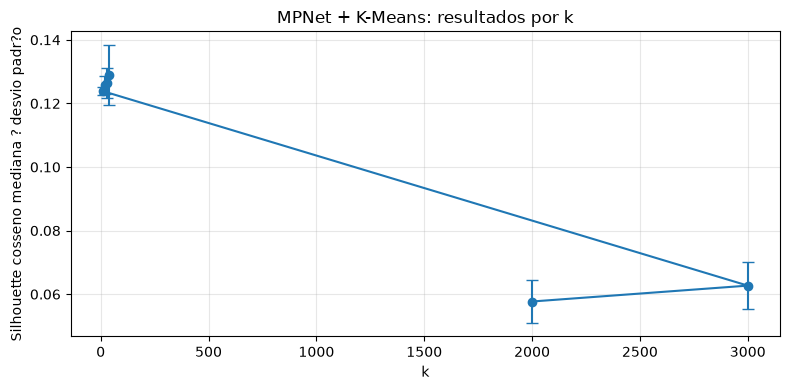

,experiment_id,k,seed,silhouette_cosine,calinski_harabasz,davies_bouldin,largest_cluster_fraction
0,mpnet_k40_seed123,40,123,0.128974,16.865424,2.594663,0.051636
1,mpnet_k30_seed2026,30,2026,0.126487,20.289623,2.688685,0.054836
2,mpnet_k20_seed123,20,123,0.125681,26.144138,2.883953,0.076582


In [11]:
ranking = (metrics.groupby("k", as_index=False)
           .agg(silhouette_median=("silhouette_cosine", "median"),
                silhouette_std=("silhouette_cosine", "std"),
                ch_median=("calinski_harabasz", "median"),
                db_median=("davies_bouldin", "median"),
                inertia_median=("inertia", "median"),
                largest_cluster_fraction=("largest_cluster_fraction", "median")))
ranking = ranking.sort_values(["silhouette_median", "silhouette_std"],
                              ascending=[False, True], na_position="last").reset_index(drop=True)
ranking.to_csv(REPORT_DIR / "ranking.csv", index=False)
display(ranking)
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(ranking.k, ranking.silhouette_median, yerr=ranking.silhouette_std,
            marker="o", capsize=4)
ax.set(xlabel="k", ylabel="Silhouette cosseno mediana ? desvio padr?o",
       title="MPNet + K-Means: resultados por k")
ax.grid(alpha=.3)
fig.tight_layout()
fig.savefig(REPORT_DIR / "silhouette_by_k.png", dpi=140, bbox_inches="tight")
plt.show()

candidate_ks = ranking.head(TOP_COMBINATIONS).k.tolist()
candidate_rows = []
for k in candidate_ks:
    group = metrics[metrics.k.eq(k)].copy()
    median = group.silhouette_cosine.median()
    chosen = group.iloc[(group.silhouette_cosine - median).abs().argsort().iloc[0]]
    candidate_rows.append(chosen)
candidates = pd.DataFrame(candidate_rows).reset_index(drop=True)
candidates.to_csv(REPORT_DIR / "candidates.csv", index=False)
display(candidates[["experiment_id", "k", "seed", "silhouette_cosine",
                    "calinski_harabasz", "davies_bouldin", "largest_cluster_fraction"]])


## 5. Inspecionar descri??es e revisar clusters

Para cada candidato, o CSV de revis?o re?ne tamanho e frequ?ncia total dos clusters, al?m de descri??es centrais e amostras. Preencha `avaliacao_qualitativa` (`coerente`, `parcialmente coerente` ou `heterogeneo`), `rotulo_humano` e `observacoes`. Os arquivos existentes n?o s?o sobrescritos. O ?ndice e o modelo de cluster valem apenas para aquela execu??o.


In [12]:
for row in candidates.itertuples(index=False):
    model = pd.read_pickle(row.model_path)
    labels = model.labels_
    assigned = train[["descricao_id", DESCRIPTION_NORMALIZED, FREQUENCY]].copy()
    assigned["cluster"] = labels
    candidate_dir = REPORT_DIR / "review" / row.experiment_id
    candidate_dir.mkdir(parents=True, exist_ok=True)
    assignments_path = candidate_dir / "assignments.csv"
    if not assignments_path.exists():
        assigned.to_csv(assignments_path, index=False)
    cluster_rows = []
    for cluster_id in sorted(np.unique(labels)):
        positions = np.flatnonzero(labels == cluster_id)
        distances = np.linalg.norm(train_embeddings[positions] - model.cluster_centers_[cluster_id], axis=1)
        central_order = positions[np.argsort(distances)[:3]]
        rng = np.random.default_rng(SPLIT_SEED + int(cluster_id))
        random_positions = rng.choice(positions, size=min(2, len(positions)), replace=False)
        examples = list(dict.fromkeys(train.iloc[np.r_[central_order, random_positions]][DESCRIPTION_NORMALIZED].astype(str)))
        cluster_rows.append({
            "cluster": int(cluster_id), "descricoes_unicas": int(len(positions)),
            "frequencia_total": int(train.iloc[positions][FREQUENCY].sum()),
            "exemplos_representativos": " | ".join(examples),
            "avaliacao_qualitativa": "", "rotulo_humano": "", "observacoes": "",
        })
    review_path = candidate_dir / "cluster_review.csv"
    if not review_path.exists():
        pd.DataFrame(cluster_rows).to_csv(review_path, index=False)
    logger.info("Materiais de revis?o: %s", candidate_dir)
    display(pd.read_csv(review_path).head(5))


2026-10-10 23:24:23,799 INFO Materiais de revis?o: reports\mpnet_kmeans\202501-202504_20261010T124411Z_01ecdc1e\review\mpnet_k40_seed123


,cluster,descricoes_unicas,frequencia_total,exemplos_representativos,avaliacao_qualitativa,rotulo_humano,observacoes
0,0,1400,10907,suco tial | fiambre kitut | estopa | alface un | polpa acerola,NaN,NaN,NaN
1,1,823,1497,rolo de espuma 09cm com cabo | rolo espuma c cabo 15cm 406 15a | rodo plastico 40 cm puxesec | rolo de la 9cm | rodo cabo aluminio rosca,NaN,NaN,NaN
2,2,299,819,cafe tradicional torrado e moido pct 500g | cafe 250g tradicional a vacuo melitta | cafe po melitta 500g tradicional | cafe teeiro 250g | cafe apresentacao ...,NaN,NaN,NaN
3,3,1420,2954,veja limp perf jasmim do caribe 1l 3130432 | nestogeno 01 400g nestle | papel hig velud vip compac fd 30m 24un | tampa de partida soprador 26 cc | organizad...,NaN,NaN,NaN
4,4,999,2642,esp pimenta calabresa marisol pct 250g | azeitona oderich 500g | azeitona preta 200g | suco tropical uva marata 200ml | mel boa vista 500g puro bisnaga,NaN,NaN,NaN


2026-10-10 23:24:24,065 INFO Materiais de revis?o: reports\mpnet_kmeans\202501-202504_20261010T124411Z_01ecdc1e\review\mpnet_k30_seed2026


,cluster,descricoes_unicas,frequencia_total,exemplos_representativos,avaliacao_qualitativa,rotulo_humano,observacoes
0,0,1421,10878,suco tial | fiambre kitut | estopa | alho descascado at | polpa de acai,NaN,NaN,NaN
1,1,1341,2591,rodo plastico 40 cm puxesec | rolo de espuma 09cm com cabo | rolo de espuma 15cm c cabo | rodo c cabo cepa plastico 30 cm | pa p lixo s cabo de madeira longo,NaN,NaN,NaN
2,2,300,820,cafe tradicional torrado e moido pct 500g | cafe 250g tradicional a vacuo melitta | cafe po melitta 500g tradicional | cafe torrado | cafe apresentacao torr...,NaN,NaN,NaN
3,3,914,3487,refrigerante de cola refri 02 l | refrigerante de cola 2 litros | refrigerante limao 2 litros | vinagre de alcool 750 ml | refrigerante pepsi black 2litros,NaN,NaN,NaN
4,4,1395,3685,detergente 500ml neutro limpol bombril | limpador azulim multiuso brisa suave 500ml | limpador multiuso 500ml lavanda bombril limpol | sabonete glamour arom...,NaN,NaN,NaN


2026-10-10 23:24:24,299 INFO Materiais de revis?o: reports\mpnet_kmeans\202501-202504_20261010T124411Z_01ecdc1e\review\mpnet_k20_seed123


,cluster,descricoes_unicas,frequencia_total,exemplos_representativos,avaliacao_qualitativa,rotulo_humano,observacoes
0,0,1259,4932,bisc zeze bolachao doce | almoco sobremesa | biscoito doce tipo maisena | bisc estrela cream cracker | marmelada de goiaba goiabada,NaN,NaN,NaN
1,1,1346,4472,refrigerante limao 2l | achocolatado liquido maratinho 200ml | suco de goiaba 1l | refrigerante sabor lata guarana | refrigerante a base de limao,NaN,NaN,NaN
2,2,1647,16049,sabao brilux limao | presunto de peru | coentro maco | petit four doce | berinjela classificacao sem caracteristicas,NaN,NaN,NaN
3,3,1782,7856,quibe assado | carne defumada tipo toucinho | carne moida | sals hot dog resf rezende fc | molho p salada kisabor mostard mel,NaN,NaN,NaN
4,4,587,1444,toalha papel coquetel l180p160fls | toalha papel 2db branca 18x19 c 1000fls petalas | papel toalha scala fd 2un 21x20cm 120f un qtd 1 00 un | toalha papel 2...,NaN,NaN,NaN


## 6. Definir taxonomia e validar na reserva

Depois de revisar os clusters, escolha um candidato abaixo e preencha `cluster_review.csv`. A c?lula cria um template de valida??o sem predi??es. Preencha `categoria_esperada` antes de executar a avalia??o. Use `FORA_DA_TAXONOMIA` para itens fora das categorias; c?lulas vazias ficam fora das m?tricas. N?o ajuste a taxonomia ap?s consultar os resultados da reserva se ela for reportada como teste independente.


In [13]:
SELECTED_EXPERIMENT_ID = None  # Ex.: mpnet_k20_seed123, ap?s revisar esse candidato.
SELECTION_REASON = ""
selected_ready = False
if SELECTED_EXPERIMENT_ID is None:
    logger.info("Revise os CSVs de cluster e escolha um candidato para continuar.")
else:
    selected_row = metrics.loc[metrics.experiment_id.eq(SELECTED_EXPERIMENT_ID)]
    if len(selected_row) != 1 or not SELECTION_REASON.strip():
        raise ValueError("Escolha um candidato desta execu??o e registre a justificativa.")
    selected = selected_row.iloc[0]
    selected_dir = REPORT_DIR / "review" / SELECTED_EXPERIMENT_ID
    review_path = selected_dir / "cluster_review.csv"
    review = pd.read_csv(review_path).fillna("")
    accepted = review[review.avaliacao_qualitativa.str.strip().str.lower().eq("coerente")
                      & review.rotulo_humano.str.strip().ne("")]
    if accepted.empty:
        logger.info("Marque clusters coerentes e preencha os r?tulos humanos antes da valida??o.")
    else:
        validation_path = selected_dir / "validation_labels.csv"
        if not validation_path.exists():
            validation[["descricao_id", DESCRIPTION_NORMALIZED, FREQUENCY]].assign(
                categoria_esperada="", observacoes=""
            ).to_csv(validation_path, index=False)
        selected_ready = True
        display(accepted[["cluster", "rotulo_humano", "descricoes_unicas", "frequencia_total"]])
        logger.info("Preencha categoria_esperada em %s e execute a pr?xima c?lula.", validation_path)


2026-10-10 23:24:24,337 INFO Revise os CSVs de cluster e escolha um candidato para continuar.


In [14]:
if selected_ready:
    review = pd.read_csv(review_path).fillna("")
    human = pd.read_csv(validation_path).fillna("")
    expected_ids = validation.set_index("descricao_id")[DESCRIPTION_NORMALIZED].sort_index()
    actual_ids = human.set_index("descricao_id")[DESCRIPTION_NORMALIZED].sort_index()
    if not expected_ids.index.equals(actual_ids.index) or expected_ids.tolist() != actual_ids.tolist():
        raise ValueError("N?o altere IDs ou descri??es; preencha somente r?tulos e observa??es.")
    human["categoria_esperada"] = human.categoria_esperada.astype(str).str.strip()
    labeled = human[human.categoria_esperada.ne("")].copy()
    if labeled.empty:
        logger.info("Valida??o pendente: preencha categoria_esperada.")
    else:
        allowed = set(review.loc[review.avaliacao_qualitativa.str.strip().str.lower().eq("coerente"),
                                "rotulo_humano"].str.strip()) - {"", "REVISAR"}
        if not set(labeled.categoria_esperada).issubset(allowed | {"FORA_DA_TAXONOMIA"}):
            raise ValueError("Use um r?tulo de cluster coerente ou FORA_DA_TAXONOMIA.")
        model = pd.read_pickle(selected.model_path)
        predicted_clusters = model.predict(validation_embeddings[
            human.index[human.categoria_esperada.ne("")].to_numpy()
        ])
        cluster_to_label = dict(zip(review.cluster, review.rotulo_humano))
        predictions = pd.Series(predicted_clusters).map(cluster_to_label).fillna("REVISAR")
        evaluated = labeled.reset_index(drop=True).copy()
        evaluated["cluster"] = predicted_clusters
        evaluated["categoria_predita"] = predictions.to_numpy()
        y_true, y_pred = evaluated.categoria_esperada, evaluated.categoria_predita
        covered = y_pred.ne("REVISAR")
        summary = pd.DataFrame([{
            "experiment_id": SELECTED_EXPERIMENT_ID, "reserva_total": len(validation),
            "rotulados": len(evaluated), "avaliacao_completa": len(evaluated) == len(validation),
            "cobertura": float(covered.mean()),
            "acuracia_incluindo_abstencoes": accuracy_score(y_true, y_pred),
            "acuracia_itens_categorizados": accuracy_score(y_true[covered], y_pred[covered]) if covered.any() else np.nan,
        }])
        labels = sorted(set(y_true) | set(y_pred))
        confusion = pd.DataFrame(confusion_matrix(y_true, y_pred, labels=labels),
                                 index=pd.Index(labels, name="esperada"), columns=labels)
        evaluation_dir = selected_dir / ("evaluation_" + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "_" + uuid4().hex[:8])
        evaluation_dir.mkdir()
        summary.to_csv(evaluation_dir / "summary.csv", index=False)
        evaluated.to_csv(evaluation_dir / "predictions.csv", index=False)
        confusion.to_csv(evaluation_dir / "confusion_matrix.csv")
        pd.DataFrame(classification_report(y_true, y_pred, output_dict=True, zero_division=0)).T.to_csv(evaluation_dir / "classification_report.csv")
        (evaluation_dir / "decision.json").write_text(json.dumps({
            "experiment_id": SELECTED_EXPERIMENT_ID, "reason": SELECTION_REASON,
            "model_path": selected.model_path, "model_name": MODEL_NAME,
        }, indent=2, ensure_ascii=False), encoding="utf-8")
        display(summary)
        display(confusion)
else:
    logger.info("Avalia??o aguardando sele??o humana e r?tulos da reserva.")


2026-10-10 23:24:24,384 INFO Avalia??o aguardando sele??o humana e r?tulos da reserva.


## 7. Experimentar descri??es novas

A c?lula usa o mesmo encoder e modelo de clustering do candidato escolhido. A associa??o a categoria usa somente o mapa de clusters revisado; grupos sem r?tulo coerente retornam `REVISAR`. O prot?tipo n?o implementa rejei??o por dist?ncia ou estimativa de confian?a.

## Registro e limita??es

Registre a base, modelo e vers?o, parti??o, par?metros, sementes, m?tricas, exemplos revisados, taxonomia, cobertura e limita??es. Os modelos de linguagem s?o pr?-treinados em dados gerais; o dom?nio de descri??es fiscais brasileiras pode exigir ajuste ou compara??o com outros embeddings. Documente a vers?o do modelo obtida do Hub para reprodutibilidade.


In [15]:
NEW_DESCRIPTIONS = ["LEITE INTEGRAL 1L", "DETERGENTE NEUTRO 500ML", "xyzdesconhecido"]
if selected_ready:
    new_vectors = encoder.encode(NEW_DESCRIPTIONS, batch_size=ENCODE_BATCH_SIZE,
                                convert_to_numpy=True, normalize_embeddings=True).astype(np.float32)
    new_clusters = model.predict(new_vectors)
    mapping = dict(zip(review.cluster, review.rotulo_humano))
    display(pd.DataFrame({DESCRIPTION_NORMALIZED: NEW_DESCRIPTIONS,
                          "cluster": new_clusters,
                          "categoria": [mapping.get(c, "REVISAR") for c in new_clusters]}))
else:
    logger.info("Selecione um experimento e revise sua taxonomia para classificar novas descri??es.")


2026-10-10 23:24:24,403 INFO Selecione um experimento e revise sua taxonomia para classificar novas descri??es.


Refer?ncias:
- [MPNet: Masked and Permuted Pre-training for Language Understanding](https://arxiv.org/abs/2004.09297)
- [Cart?o do modelo multil?ngue](https://huggingface.co/sentence-transformers/paraphrase-multilingual-mpnet-base-v2)
- [Sentence Transformers: modelos pr?-treinados](https://sbert.net/docs/sentence_transformer/pretrained_models.html)
- [K-Means do scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html)
